## Bài tập về nhà

**Bài 1:**

Hệ số chặn (Intercept): [4.20634019]
Hệ số hồi quy (Coefficients): [[2.9902591]]
Mean Squared Error (MSE): 0.9177532469714291
R^2 score: 0.6521157503858556



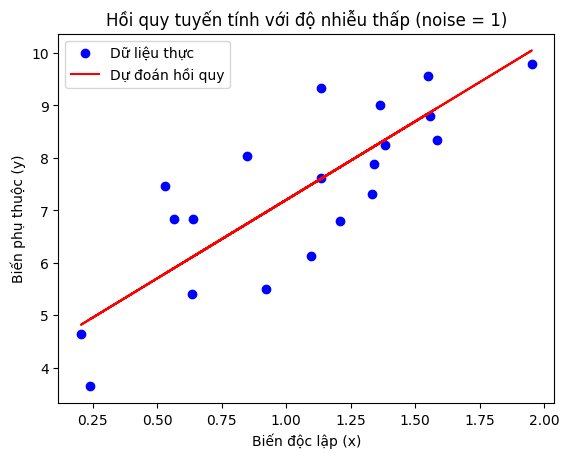

Hệ số chặn (Intercept): [4.61902057]
Hệ số hồi quy (Coefficients): [[2.9707773]]
Mean Squared Error (MSE): 8.25977922274286
R^2 score: 0.1354996889186385



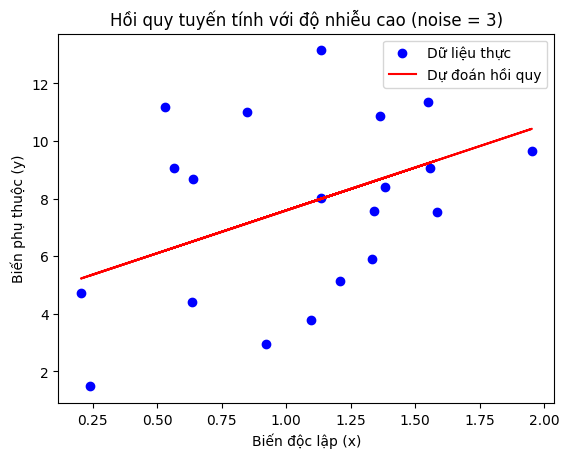

In [2]:
# Thư viện
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Điều kiện sinh dữ liệu ban đầu (độ nhiễu thấp: noise = 1)
# Tạo dữ liệu giả lập
np.random.seed(0)
x = 2 * np.random.rand(100, 1)
y = 4 + 3 * x + 1 * np.random.randn(100, 1) # Đường thẳng với nhiễu thấp

# Chia dữ liệu
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Tạo mô hình hồi quy tuyến tính
model = LinearRegression()

# Huấn luyện mô hình
model.fit(x_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(x_test)

# Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# In kết quả
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số hồi quy (Coefficients): {model.coef_}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R^2 score: {r2}\n")

# Vẽ biểu đồ
plt.scatter(x_test, y_test, color="blue", label="Dữ liệu thực")
plt.plot(x_test, y_pred, color="red", label="Dự đoán hồi quy")
plt.title("Hồi quy tuyến tính với độ nhiễu thấp (noise = 1)")
plt.xlabel("Biến độc lập (x)")
plt.ylabel("Biến phụ thuộc (y)")
plt.legend()
plt.show()

# 2. Thay đổi điều kiện sinh dữ liệu (tăng độ nhiễu: noise = 3)
# Tạo dữ liệu giả lập
np.random.seed(0)
x = 2 * np.random.rand(100, 1)
y = 4 + 3 * x + 3 * np.random.randn(100, 1) # Tăng độ nhiễu lên 3 lần

# Chia dữ liệu
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Tạo mô hình hồi quy tuyến tính
model = LinearRegression()

# Huấn luyện mô hình
model.fit(x_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(x_test)

# Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# In kết quả
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số hồi quy (Coefficients): {model.coef_}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R^2 score: {r2}\n")

# Vẽ biểu đồ
plt.scatter(x_test, y_test, color="blue", label="Dữ liệu thực")
plt.plot(x_test, y_pred, color="red", label="Dự đoán hồi quy")
plt.title("Hồi quy tuyến tính với độ nhiễu cao (noise = 3)")
plt.xlabel("Biến độc lập (x)")
plt.ylabel("Biến phụ thuộc (y)")
plt.legend()
plt.show()


**Bài 2:**

In [3]:
# Thư viện
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Tải dữ liệu hoa Iris trong thư viện sklearn
iris = load_iris()
X = iris['data'] # Các đặc trưng (features)
y = iris['target'] # Các nhãn (target)

# Chọn ra hai loại hoa (0 và 1) để thực hiện phân loại nhị phân
X = X[y != 2] # Loại bỏ lớp 2
y = y[y != 2] # Chỉ giữ lại lớp 0 và 1

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tạo mô hình Logistic Regression
model = LogisticRegression()

# Huấn luyện mô hình trên tập huấn luyện
model.fit(X_train, y_train)

# Dự đoán xác suất trên tập kiểm tra
y_prob = model.predict_proba(X_test)[:, 1] # Xác suất thuộc lớp 1

# 1. Dự đoán với ngưỡng mặc định (threshold = 0.5)
y_pred_05 = (y_prob >= 0.5).astype(int)

# Đánh giá mô hình (ngưỡng 0.5)
accuracy_05 = accuracy_score(y_test, y_pred_05)
conf_matrix_05 = confusion_matrix(y_test, y_pred_05)
class_report_05 = classification_report(y_test, y_pred_05)

# In kết quả
print(f"Ngưỡng 0.5 - Độ chính xác (Accuracy): {accuracy_05}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix_05)
print("Báo cáo phân loại (Classification Report):")
print(class_report_05)

# 2. Đổi ngưỡng dự đoán xác suất thành 0.6
y_pred_06 = (y_prob >= 0.6).astype(int)

# Đánh giá mô hình (ngưỡng 0.6)
accuracy_06 = accuracy_score(y_test, y_pred_06)
conf_matrix_06 = confusion_matrix(y_test, y_pred_06)
class_report_06 = classification_report(y_test, y_pred_06)

# In kết quả
print(f"Ngưỡng 0.6 - Độ chính xác (Accuracy): {accuracy_06}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix_06)
print("Báo cáo phân loại (Classification Report):")
print(class_report_06)

# 3. Đổi ngưỡng dự đoán xác suất thành 0.7
y_pred_07 = (y_prob >= 0.7).astype(int)

# Đánh giá mô hình (ngưỡng 0.7)
accuracy_07 = accuracy_score(y_test, y_pred_07)
conf_matrix_07 = confusion_matrix(y_test, y_pred_07)
class_report_07 = classification_report(y_test, y_pred_07)

# In kết quả
print(f"Ngưỡng 0.7 - Độ chính xác (Accuracy): {accuracy_07}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix_07)
print("Báo cáo phân loại (Classification Report):")
print(class_report_07)


Ngưỡng 0.5 - Độ chính xác (Accuracy): 1.0
Ma trận nhầm lẫn (Confusion Matrix):
[[12  0]
 [ 0  8]]
Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00         8

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20

Ngưỡng 0.6 - Độ chính xác (Accuracy): 1.0
Ma trận nhầm lẫn (Confusion Matrix):
[[12  0]
 [ 0  8]]
Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00         8

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20

Ngưỡng 0.7 - Độ chính xác (Accuracy): 1.0
Ma trận nhầm lẫn (Conf

**Bài 3:**

In [4]:
# Thư viện
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải tập dữ liệu Boston Housing
boston = fetch_openml(name="boston", version=1, as_frame=False, parser="auto")
X = boston.data.astype(float) # Các đặc trưng (features)
y = boston.target.astype(float) # Biến mục tiêu (target - Giá nhà)

# 2. Phân chia dữ liệu thành tập huấn luyện và tập kiểm tra
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Tạo mô hình hồi quy tuyến tính
model = LinearRegression()

# Huấn luyện mô hình trên tập huấn luyện
model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# 4. Tính toán các chỉ số đánh giá: MSE và R^2 score cho tập kiểm tra
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# In kết quả
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số hồi quy (Coefficients): {model.coef_}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R^2 score: {r2}")


Hệ số chặn (Intercept): 30.246750993923776
Hệ số hồi quy (Coefficients): [-1.13055924e-01  3.01104641e-02  4.03807204e-02  2.78443820e+00
 -1.72026334e+01  4.43883520e+00 -6.29636221e-03 -1.44786537e+00
  2.62429736e-01 -1.06467863e-02 -9.15456240e-01  1.23513347e-02
 -5.08571424e-01]
Mean Squared Error (MSE): 24.291119474973485
R^2 score: 0.6687594935356325
